# **CONSUMER BEHAVIOUR AND E-COMMERCE**
### **Objective:** Analyze the factors influencing consumer purchasing behavior in e-commerce and identify significant relationships between these factors
####


In [1]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
os.makedirs('pictures', exist_ok=True)
import pandas as pd

In [4]:
df = pd.read_csv('index.csv')
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Review Rating,Shipping Type,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,3.1,Express,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,3.1,Express,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,3.1,Free Shipping,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,3.5,Next Day Air,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,2.7,Free Shipping,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...
525,526,51,Male,Coat,Outerwear,37,Iowa,3.2,Next Day Air,Debit Card,Monthly
526,527,51,Male,Pants,Clothing,52,New Jersey,4.9,Standard,Cash,Monthly
527,528,21,Male,T-shirt,Clothing,23,South Carolina,4.3,Next Day Air,Bank Transfer,Every 3 Months
528,529,34,Male,Sneakers,Footwear,88,Maryland,3.2,Express,Cash,Annually


## **Data Preprocessing**

In [5]:
missing_values = df.isnull().sum()
print(missing_values)

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Review Rating             0
Shipping Type             0
Payment Method            0
Frequency of Purchases    0
dtype: int64


In [6]:
duplicates = df.duplicated().sum()
print(f'Duplicate rows: {duplicates}')

Duplicate rows: 0


In [7]:
df.drop_duplicates(inplace=True)

## **Removing outliers using Z-Score method**

In [8]:
mean = df['Purchase Amount (USD)'].mean()
std_dev = df['Purchase Amount (USD)'].std()
threshold_upper = mean + 3 * std_dev
threshold_lower = mean - 3 * std_dev

df = df[(df['Purchase Amount (USD)'] < threshold_upper) & (df['Purchase Amount (USD)'] > threshold_lower)]


In [9]:
print(f"Upper threshold: {threshold_upper}")
print(f"Lower threshold: {threshold_lower}")

# Remove outliers based on the Z-score method
df_cleaned = df[(df['Purchase Amount (USD)'] <= threshold_upper) & (df['Purchase Amount (USD)'] >= threshold_lower)]

# Print the number of rows before and after removing outliers
print(f"Rows before removing outliers: {len(df)}")
print(f"Rows after removing outliers: {len(df_cleaned)}")

Upper threshold: 130.39995884534918
Lower threshold: -11.233921109500123
Rows before removing outliers: 530
Rows after removing outliers: 530


## **Descriptive statistics & Exploratory Data Analysis (EDA)**

In [10]:
statistics = df['Purchase Amount (USD)'].describe()
print(statistics)

# Other statistics: skewness and kurtosis
skewness = df['Purchase Amount (USD)'].skew()
kurtosis = df['Purchase Amount (USD)'].kurt()
print(f"Skewness: {skewness}")
print(f"Kurtosis: {kurtosis}")


count    530.000000
mean      59.583019
std       23.605647
min       20.000000
25%       39.000000
50%       59.000000
75%       81.000000
max      100.000000
Name: Purchase Amount (USD), dtype: float64
Skewness: 0.02291611657764802
Kurtosis: -1.275352767588664


In [11]:
# Mean
mean = df['Purchase Amount (USD)'].mean()
print(f"Mean: {mean}")

# Median
median = df['Purchase Amount (USD)'].median()
print(f"Median: {median}")

# Standard Deviation
std_dev = df['Purchase Amount (USD)'].std()
print(f"Standard Deviation: {std_dev}")

# Interquartile Range
Q1 = df['Purchase Amount (USD)'].quantile(0.25)
Q3 = df['Purchase Amount (USD)'].quantile(0.75)
IQR = Q3 - Q1
print(f"Interquartile Range: {IQR}")

# Skewness
skewness = df['Purchase Amount (USD)'].skew()
print(f"Skewness: {skewness}")

# Correlation Coefficient (Example: with 'Age')
correlation = df['Purchase Amount (USD)'].corr(df['Age'])
print(f"Correlation between Purchase Amount and Age: {correlation}")


Mean: 59.58301886792453
Median: 59.0
Standard Deviation: 23.605646659141552
Interquartile Range: 42.0
Skewness: 0.02291611657764802
Correlation between Purchase Amount and Age: -0.045365173055253345


#### **Grouping the Data by Age, Gender, Category, etc.**

In [12]:
# Define age bins and labels
age_bins = [18, 24, 34, 44, 54, 64, 100]
age_labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']

# Create a new column 'Age Group'
df['Age Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, right=False)

# Check the distribution
print(df[['Age', 'Age Group']].head())


   Age Age Group
0   55     55-64
1   19     18-24
2   50     45-54
3   21     18-24
4   45     45-54


In [13]:
# Average purchase amount for each age group
age_group_stats = df.groupby('Age Group', observed=True)['Purchase Amount (USD)'].mean()
print(age_group_stats)

Age Group
18-24    60.736842
25-34    58.009615
35-44    63.355140
45-54    59.250000
55-64    59.130435
65+      56.285714
Name: Purchase Amount (USD), dtype: float64


#### **Group by Gender and How do purchasing habits vary across different age groups and genders?**

In [14]:
gender_stats = df.groupby('Gender')['Purchase Amount (USD)'].mean()
print(gender_stats)

Gender
Male    59.583019
Name: Purchase Amount (USD), dtype: float64


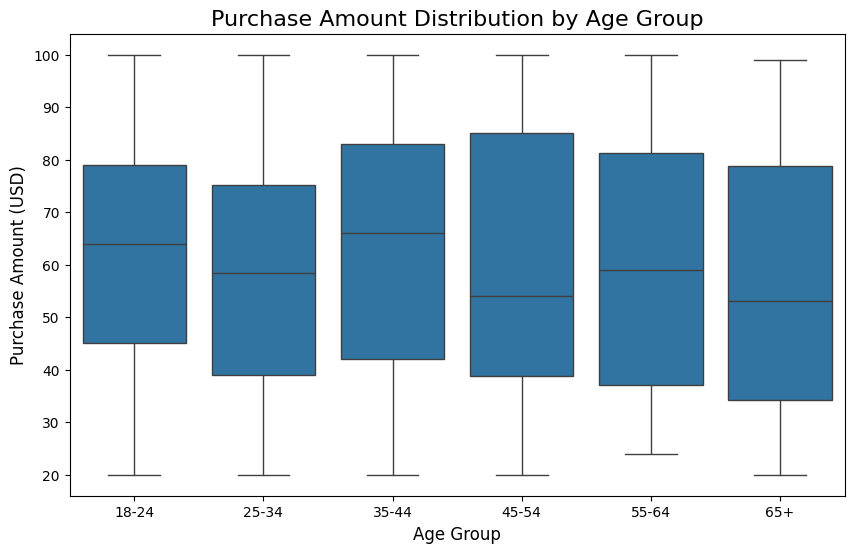

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Box plot for Purchase Amount across different Age Groups
plt.figure(figsize=(10, 6))
sns.boxplot(x='Age Group', y='Purchase Amount (USD)', data=df)

# Title and labels
plt.title('Purchase Amount Distribution by Age Group', fontsize=16)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Purchase Amount (USD)', fontsize=12)

# Show plot
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/purchase_amount_distribution_by_age_group.jpg', format='jpg', bbox_inches='tight')
plt.show()


#### **Find the most frequent item purchased in each category**

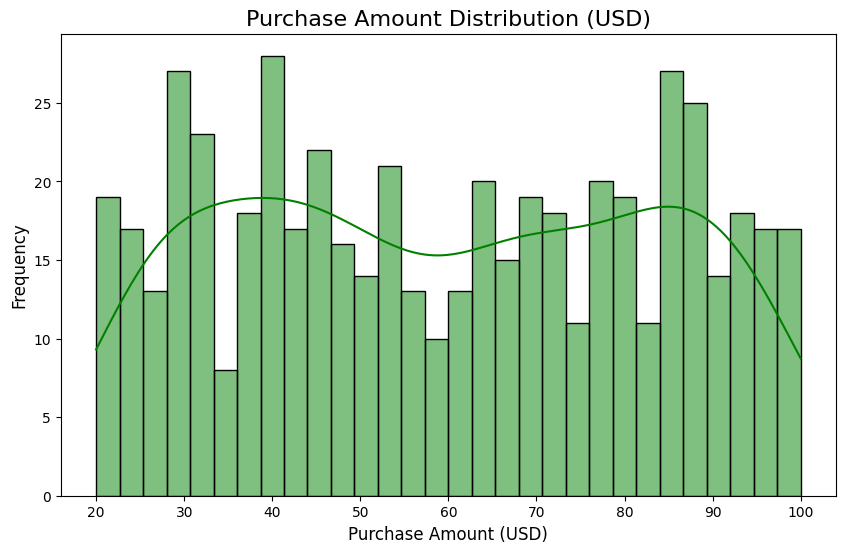

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot a histogram for Purchase Amount Distribution
plt.figure(figsize=(10, 6))

# Create a histogram with KDE (Kernel Density Estimate) for smoothness
sns.histplot(df['Purchase Amount (USD)'], bins=30, kde=True, color='green', edgecolor='black')

# Title and labels
plt.title('Purchase Amount Distribution (USD)', fontsize=16)
plt.xlabel('Purchase Amount (USD)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Show pl
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/purchase_amount_distribution_usd.jpg', format='jpg', bbox_inches='tight')
plt.show()

Category
Accessories    Jewelry
Clothing       Sweater
Footwear         Shoes
Outerwear         Coat
Name: Item Purchased, dtype: object


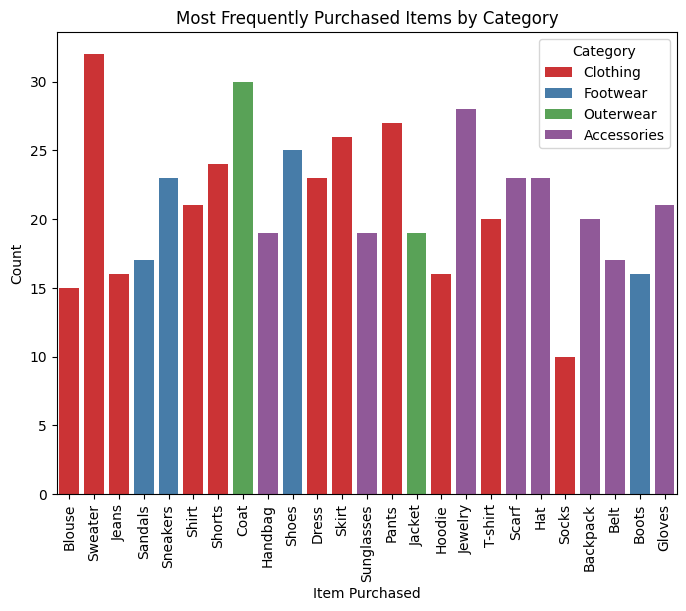

In [17]:
# Plot the most frequently purchased items by category
import seaborn as sns
import matplotlib.pyplot as plt

category_stats = df.groupby('Category')['Item Purchased'].apply(lambda x: x.mode()[0])
print(category_stats)

plt.figure(figsize=(8, 6))
sns.countplot(x='Item Purchased', data=df, hue='Category', palette='Set1')
plt.xticks(rotation=90)
plt.title('Most Frequently Purchased Items by Category')
plt.xlabel('Item Purchased')
plt.ylabel('Count')
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/most_frequently_purchased_items_by_category.jpg', format='jpg', bbox_inches='tight')
plt.show()


In [18]:
# Optional: To focus on specific correlations (e.g., between Purchase Amount and Age):
correlation_purchase = df[['Purchase Amount (USD)', 'Age', 'Review Rating']].corr()
print("\nCorrelation between Purchase Amount, Age, and Review Rating:")
print(correlation_purchase)


Correlation between Purchase Amount, Age, and Review Rating:
                       Purchase Amount (USD)       Age  Review Rating
Purchase Amount (USD)               1.000000 -0.045365      -0.040617
Age                                -0.045365  1.000000       0.024140
Review Rating                      -0.040617  0.024140       1.000000


#### **Which product category generates the highest total sales revenue?**

Category
Accessories    10027
Clothing       13636
Footwear        4982
Outerwear       2934
Name: Purchase Amount (USD), dtype: int64


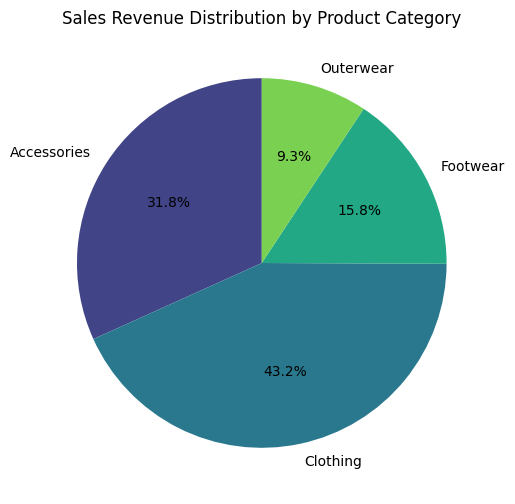

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total sales revenue by category
category_revenue = df.groupby('Category')['Purchase Amount (USD)'].sum()
print(category_revenue)

# Reset the index to ensure 'Category' is a column for the pie chart
category_revenue = category_revenue.reset_index()

# Plotting the pie chart
plt.figure(figsize=(6, 6))
plt.pie(category_revenue['Purchase Amount (USD)'], labels=category_revenue['Category'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('viridis', len(category_revenue)))

# Title for the pie chart
plt.title('Sales Revenue Distribution by Product Category')

# Display the pie chart
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/sales_revenue_distribution_by_product_category.jpg', format='jpg', bbox_inches='tight')
plt.show()


#### **Correlation between Review Rating and Purchase Amount**

Category
Accessories    3.762353
Clothing       3.758261
Footwear       3.837037
Outerwear      3.661224
Name: Review Rating, dtype: float64
                       Review Rating  Purchase Amount (USD)
Review Rating               1.000000              -0.040617
Purchase Amount (USD)      -0.040617               1.000000


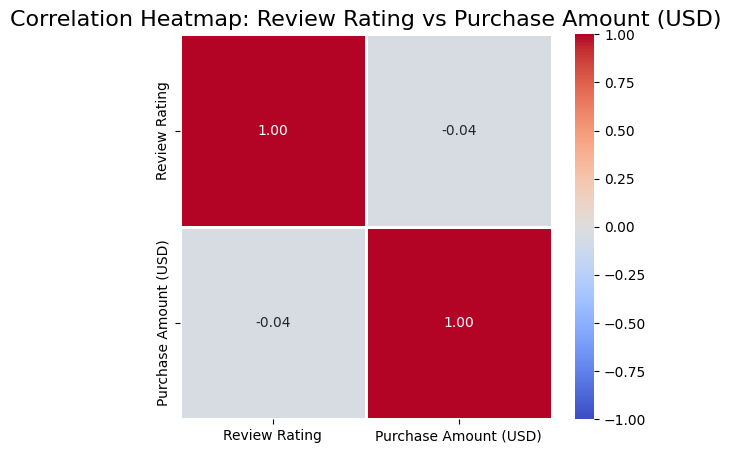

In [20]:
# Group by Category and calculate the average review rating
review_stats = df.groupby('Category')['Review Rating'].mean()

# Display the result
print(review_stats)

# Calculate the correlation between Review Rating and Purchase Amount
correlation = df[['Review Rating', 'Purchase Amount (USD)']].corr()

# Display the result
print(correlation)

# Plotting the heatmap
plt.figure(figsize=(6, 5))  # Adjust the size of the plot
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=1, fmt=".2f")

# Title and labels
plt.title('Correlation Heatmap: Review Rating vs Purchase Amount (USD)', fontsize=16)
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/correlation_heatmap_review_rating_vs_purchase_amount_usd.jpg', format='jpg', bbox_inches='tight')
plt.show()

#### **What is the average review rating for items in each category?**

      Category  Review Rating
0  Accessories       3.762353
1     Clothing       3.758261
2     Footwear       3.837037
3    Outerwear       3.661224


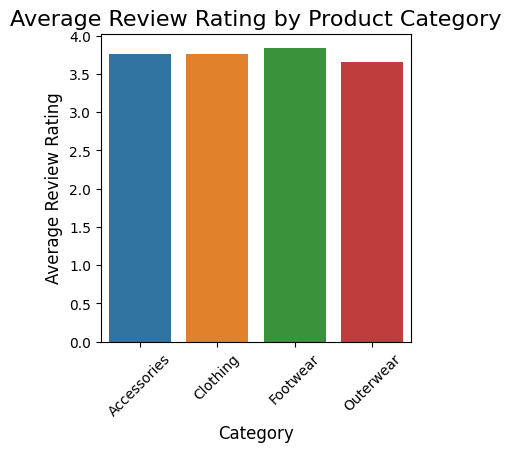

                       Review Rating  Purchase Amount (USD)
Review Rating               1.000000              -0.040617
Purchase Amount (USD)      -0.040617               1.000000


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group by Category and calculate the average review rating per category
review_stats = df.groupby('Category')['Review Rating'].mean().reset_index()
# Display the result
print(review_stats)

# Plotting the bar chart for the average review ratings across different categories
plt.figure(figsize=(4, 4))
sns.barplot(x='Category', y='Review Rating', data=review_stats, hue='Category')

# Title and labels
plt.title('Average Review Rating by Product Category', fontsize=16)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Average Review Rating', fontsize=12)
plt.xticks(rotation=45)  # Rotate category names for better readability
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/average_review_rating_by_product_category.jpg', format='jpg', bbox_inches='tight')
plt.show()

# Calculate the correlation between Review Rating and Purchase Amount
correlation = df[['Review Rating', 'Purchase Amount (USD)']].corr()
# Display the result
print(correlation)

#### **What are the most common shipping types chosen by customers? How do payment methods vary among different customer segments?**


Payment Method  Bank Transfer  Cash  Credit Card  Debit Card  PayPal  Venmo
Age Group                                                                  
18-24                      11     7            9          14       8      8
25-34                      15    11           23          22      16     17
35-44                      15    19           19          17      20     17
45-54                      12    15           22          17      19     15
55-64                      13    23           17           9      18     12
65+                        13    10           11          14      11     11


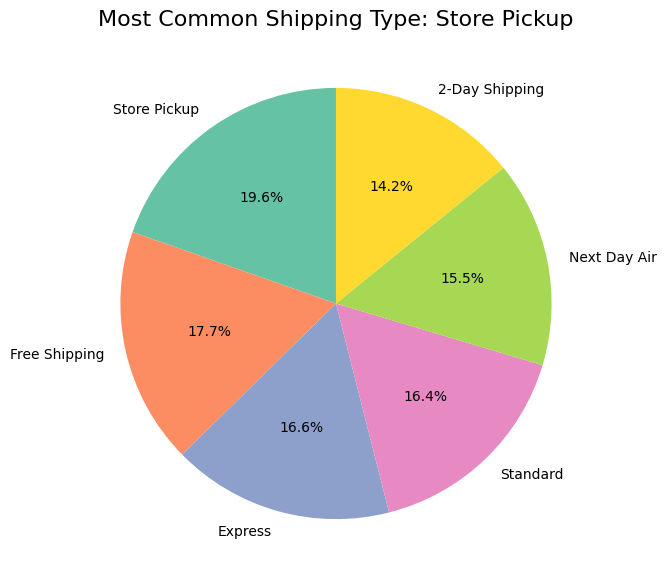

In [22]:
# Find the most common shipping type
shipping_stats = df['Shipping Type'].mode()[0]  # Get the most common shipping type (mode returns a series)

# Group by Age Group and Payment Method, then calculate the counts
payment_method_stats = pd.crosstab(df['Age Group'], df['Payment Method'])

# Display the result
print(payment_method_stats)

# Count the occurrences of each shipping type
shipping_type_counts = df['Shipping Type'].value_counts()

# Plotting the pie chart for the shipping type distribution
plt.figure(figsize=(7, 7))
plt.pie(shipping_type_counts, labels=shipping_type_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2', len(shipping_type_counts)))
plt.title(f'Most Common Shipping Type: {shipping_stats}', fontsize=16)
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/shipping_type_distribution.jpg', format='jpg', bbox_inches='tight')
plt.show()


#### **How does the frequency of purchases affect the average purchase amount per customer?**

Frequency of Purchases
Annually          58.884211
Bi-Weekly         58.447761
Every 3 Months    59.214286
Fortnightly       59.178571
Monthly           58.126761
Quarterly         65.353846
Weekly            58.692308
Name: Purchase Amount (USD), dtype: float64


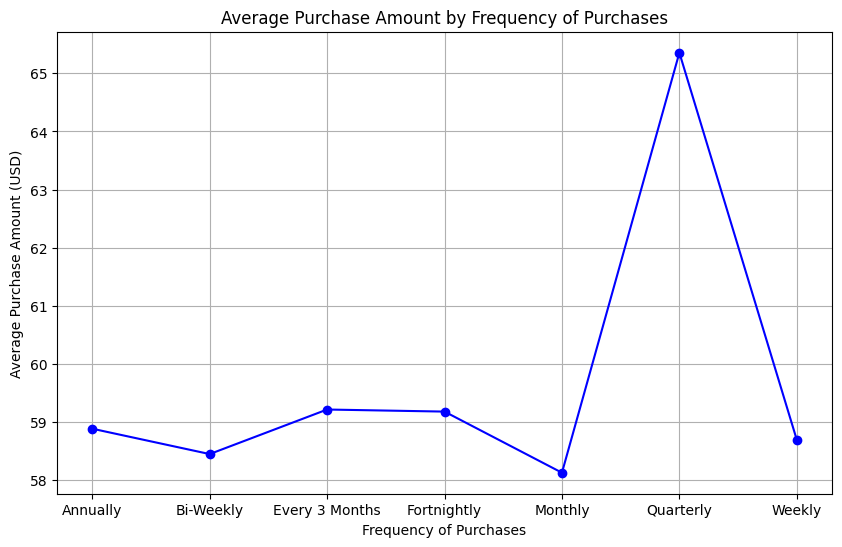

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Frequency of Purchases and calculate the average purchase amount
frequency_stats = df.groupby('Frequency of Purchases')['Purchase Amount (USD)'].mean()
# Display the result
print(frequency_stats)

# Plot the frequency of purchases vs. average purchase amount (Line Chart)
plt.figure(figsize=(10, 6))
plt.plot(frequency_stats.index, frequency_stats.values, marker='o', linestyle='-', color='b')  # Line chart
plt.title('Average Purchase Amount by Frequency of Purchases')
plt.xlabel('Frequency of Purchases')
plt.ylabel('Average Purchase Amount (USD)')
plt.grid(True)  # Adds grid lines for better readability
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/average_purchase_amount_by_frequency_of_purchases.jpg', format='jpg', bbox_inches='tight')
plt.show()


Location
Rhode Island     76.750000
Pennsylvania     73.000000
Arizona          71.142857
Massachusetts    70.750000
West Virginia    70.470588
Utah             70.454545
Washington       69.500000
Oklahoma         68.266667
New Mexico       66.750000
Alabama          65.900000
Name: Purchase Amount (USD), dtype: float64


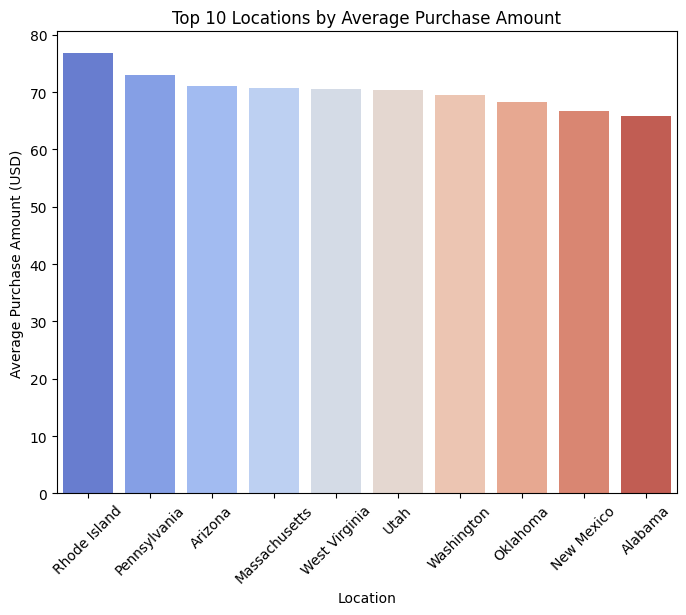

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Location and calculate the average purchase amount
location_stats = df.groupby('Location')['Purchase Amount (USD)'].mean()

# Sort by average purchase amount in descending order and select the top 10
top_location_stats = location_stats.sort_values(ascending=False).head(10)
print(top_location_stats)

# Plot average purchase amount by location (Top 10 locations)
plt.figure(figsize=(8, 6))
sns.barplot(x=top_location_stats.index, y=top_location_stats.values, hue=top_location_stats.index, palette='coolwarm')
plt.title('Top 10 Locations by Average Purchase Amount')
plt.xlabel('Location')
plt.ylabel('Average Purchase Amount (USD)')
plt.xticks(rotation=45)
os.makedirs('pictures', exist_ok=True)
plt.savefig('pictures/top_10_locations_by_average_purchase_amount.jpg', format='jpg', bbox_inches='tight')
plt.show()


## **Hypothesis Testing**

In [25]:
# Pearson's correlation between Age and Purchase Amount
from scipy.stats import pearsonr

correlation_age, p_value_age = pearsonr(df['Age'], df['Purchase Amount (USD)'])
print(f"Pearson Correlation: {correlation_age:.2f}")
print(f"P-value: {p_value_age:.4f}")

# Check if p-value < 0.05 to reject or fail to reject the null hypothesis
if p_value_age < 0.05:
    print("Reject the null hypothesis: There is a significant relationship between Age and Purchase Amount.")
else:
    print("Fail to reject the null hypothesis: No significant relationship between Age and Purchase Amount.")

Pearson Correlation: -0.05
P-value: 0.2972
Fail to reject the null hypothesis: No significant relationship between Age and Purchase Amount.


## **Confidence Interval**

In [32]:
import numpy as np
import scipy.stats as stats

# Calculate the sample mean and standard deviation
sample_mean = np.mean(df['Purchase Amount (USD)'])
sample_std = np.std(df['Purchase Amount (USD)'], ddof=1)  # Sample standard deviation
n = len(df['Purchase Amount (USD)'])

# Confidence level (95%)
confidence_level = 0.95

# Calculate the t-score for 95% confidence level and n-1 degrees of freedom
t_score = stats.t.ppf((1 + confidence_level) / 2, df=n-1)

# Calculate the margin of error
margin_of_error = t_score * (sample_std / np.sqrt(n))

# Calculate the confidence interval
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

# Print the results
print(f"Sample Mean: {sample_mean:.2f}")
print(f"Sample Standard Deviation: {sample_std:.2f}")
print(f"Sample Size: {n}")
print(f"Confidence Interval (95%): ({ci_lower:.2f}, {ci_upper:.2f})")


Sample Mean: 59.58
Sample Standard Deviation: 23.61
Sample Size: 530
Confidence Interval (95%): (57.57, 61.60)
